# 电商用户行为分析：转化漏斗与用户分层

## 项目背景
运营团队希望弄清楚三件事：用户从浏览到购买的转化链路在哪里流失、不同价值的用户如何分层、哪些商品类目效率更高。本项目基于电商用户行为数据，用 MySQL 取数、Python 完成分析与可视化。

## 数据说明
- 数据来源：阿里淘宝用户行为公开数据集（抽样 10 万条）
- 时间范围：2014-11-18 ~ 2014-12-18
- 数据表：`user_behavior_new`

| 字段 | 含义 |
|---|---|
| user_id | 用户 ID |
| item_id | 商品 ID |
| behavior_type | 行为类型：1 浏览 pv / 2 加购 cart / 3 收藏 fav / 4 购买 buy |
| item_category | 商品类目 ID |
| time | 行为时间（精确到小时） |

## 分析工具
MySQL 取数 + Python（pandas / numpy / matplotlib）分析与可视化

In [1]:
import os
import pymysql
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 中文显示
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 数据库连接配置（本地运行前改成自己的 MySQL 账号密码）
DB_CONF = dict(host='localhost', port=3306, user='root',
               password='539258', database='taobao_analysis', charset='utf8mb4')

def query(sql):
    conn = pymysql.connect(**DB_CONF)
    df = pd.read_sql(sql, conn)
    conn.close()
    return df

BEHAVIOR_MAP = {1: '浏览pv', 2: '加购cart', 3: '收藏fav', 4: '购买buy'}
IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)

## 一、数据概览

先看四类行为各自产生了多少条记录，判断整体行为结构是否合理。

```sql
SELECT behavior_type, COUNT(*) AS cnt
FROM user_behavior_new
GROUP BY behavior_type
ORDER BY behavior_type;
```

In [2]:
sql = """
SELECT behavior_type, COUNT(*) AS cnt
FROM user_behavior_new
GROUP BY behavior_type ORDER BY behavior_type
"""
df_behavior = query(sql)
df_behavior['label'] = df_behavior['behavior_type'].map(BEHAVIOR_MAP)
df_behavior['pct'] = (df_behavior['cnt'] / df_behavior['cnt'].sum() * 100).round(1)
df_behavior

C:\Users\pzk\AppData\Local\Temp\ipykernel_31240\1607654754.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,behavior_type,cnt,label,pct
0,1,94543,浏览pv,94.5
1,2,1853,加购cart,1.9
2,3,2652,收藏fav,2.7
3,4,952,购买buy,1.0


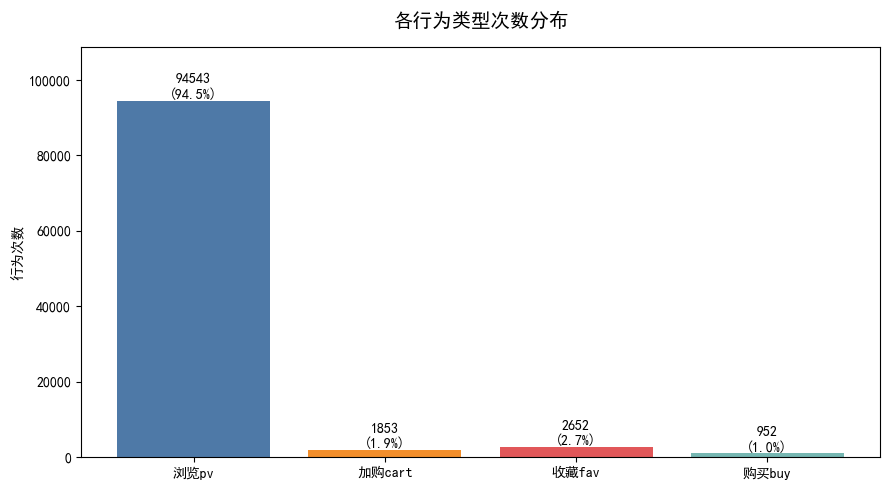

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(df_behavior['label'], df_behavior['cnt'],
              color=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2'])
ax.set_title('各行为类型次数分布', fontsize=14, pad=15)
ax.set_ylabel('行为次数')
for b, c, p in zip(bars, df_behavior['cnt'], df_behavior['pct']):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(),
            f'{c}\n({p}%)', ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, df_behavior['cnt'].max() * 1.15)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/behavior_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**结论：** 浏览行为占 94.5%，加购、收藏、购买合计约 5.5%，符合电商"浏览远多于成交"的正常结构。

## 二、转化漏斗分析

### 口径说明
漏斗按"层层包含"统计：进入下一层的用户一定也完成了上一层行为。

- 第 1 层：所有浏览 pv 用户
- 第 2 层：浏览且加购 cart
- 第 3 层：浏览、加购且收藏 fav
- 第 4 层：浏览、加购、收藏且购买 buy

逐级转化率 = 本层用户数 / 上一层用户数；整体转化率 = 购买用户 / 浏览用户。

```sql
SELECT
  COUNT(DISTINCT CASE WHEN behavior_type=1 THEN user_id END) AS pv_users,
  COUNT(DISTINCT CASE WHEN behavior_type=2 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    THEN user_id END) AS pv_cart,
  COUNT(DISTINCT CASE WHEN behavior_type=3 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=2)
    THEN user_id END) AS pv_cart_fav,
  COUNT(DISTINCT CASE WHEN behavior_type=4 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=2)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=3)
    THEN user_id END) AS pv_cart_fav_buy
FROM user_behavior_new;
```

In [4]:
sql = """
SELECT
  COUNT(DISTINCT CASE WHEN behavior_type=1 THEN user_id END) AS pv_users,
  COUNT(DISTINCT CASE WHEN behavior_type=2 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    THEN user_id END) AS pv_cart,
  COUNT(DISTINCT CASE WHEN behavior_type=3 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=2)
    THEN user_id END) AS pv_cart_fav,
  COUNT(DISTINCT CASE WHEN behavior_type=4 AND user_id IN
    (SELECT user_id FROM user_behavior_new WHERE behavior_type=1)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=2)
    AND user_id IN (SELECT user_id FROM user_behavior_new WHERE behavior_type=3)
    THEN user_id END) AS pv_cart_fav_buy
FROM user_behavior_new
"""
df_funnel = query(sql)

stages = ['浏览pv', '加购cart', '收藏fav', '购买buy']
users = [int(df_funnel['pv_users'][0]), int(df_funnel['pv_cart'][0]),
         int(df_funnel['pv_cart_fav'][0]), int(df_funnel['pv_cart_fav_buy'][0])]
rates = ['']
for i in range(1, 4):
    rates.append(f'{users[i]/users[i-1]*100:.0f}%')

df_funnel_show = pd.DataFrame({'阶段': stages, '用户数': users, '逐级转化率': rates})
df_funnel_show

C:\Users\pzk\AppData\Local\Temp\ipykernel_31240\1607654754.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


,阶段,用户数,逐级转化率
0,浏览pv,898,
1,加购cart,327,36%
2,收藏fav,201,61%
3,购买buy,131,65%


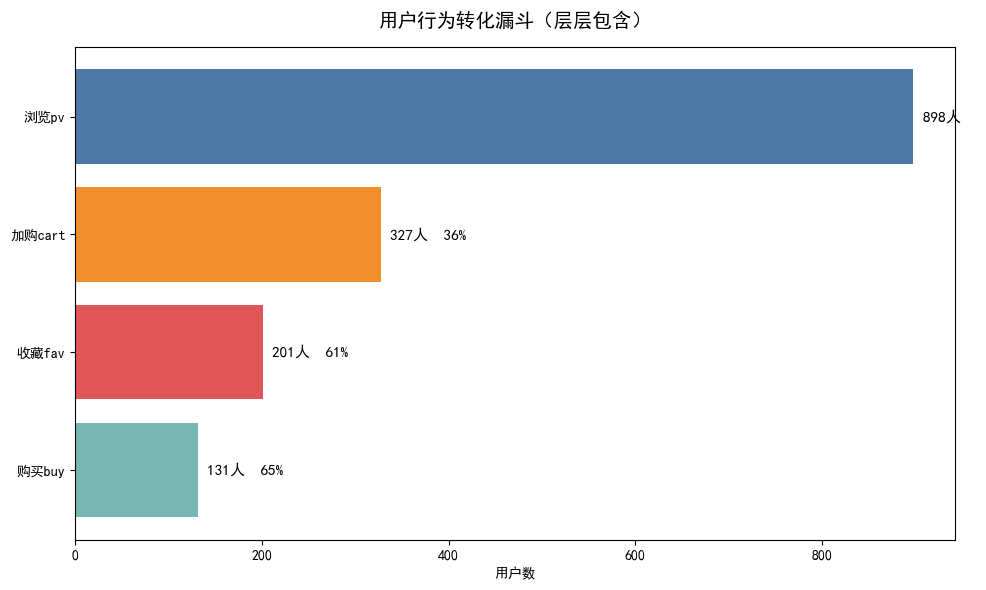

整体转化率（浏览→购买）：14.6%


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(stages, users, color=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2'])
ax.set_title('用户行为转化漏斗（层层包含）', fontsize=14, pad=15)
ax.set_xlabel('用户数')
ax.invert_yaxis()
for i, (v, r) in enumerate(zip(users, rates)):
    ax.text(v + 10, i, f'{v}人  {r}', va='center', fontsize=11)
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/funnel.png', dpi=150, bbox_inches='tight')
plt.show()

overall = users[-1] / users[0] * 100
print(f'整体转化率（浏览→购买）：{overall:.1f}%')

**结论：**
- 浏览→加购转化率仅 36%，是整条链路流失最严重的环节，约 64% 的用户浏览后未进一步互动。
- 加购→收藏 61%、收藏→购买 65%，说明走到中后段的用户购买意向较强。
- 整体浏览→购买转化率约 14.6%。
- 运营建议：重点优化商品详情页、价格与推荐，提升浏览到加购的转化。

## 三、用户价值分层（RF 模型）

### 指标口径
经典 RFM 包含 R（最近购买间隔）、F（购买频次）、M（消费金额）。本数据集没有金额字段，因此采用 RF 两维：

- **R (Recency)**：用户最近一次购买距基准日（数据最晚日期 2014-12-18）的天数，越小越活跃
- **F (Frequency)**：统计周期内购买次数，越多价值越高

以中位数为阈值将 R、F 各分为高低两组，交叉得到四类购买用户；未产生购买行为的单列为"潜在未转化用户"。

```sql
SELECT user_id,
       COUNT(*) AS F,
       MAX(DATE(STR_TO_DATE(time, '%Y-%m-%d %H'))) AS last_buy
FROM user_behavior_new
WHERE behavior_type = 4
GROUP BY user_id;
```

In [6]:
buy_sql = """
SELECT user_id, COUNT(*) AS F,
       MAX(DATE(STR_TO_DATE(time, '%Y-%m-%d %H'))) AS last_buy
FROM user_behavior_new WHERE behavior_type=4 GROUP BY user_id
"""
buy_df = query(buy_sql)
all_df = query("SELECT DISTINCT user_id FROM user_behavior_new")

buy_df['last_buy'] = pd.to_datetime(buy_df['last_buy'])
base_date = buy_df['last_buy'].max()
buy_df['R'] = (base_date - buy_df['last_buy']).dt.days

r_med = buy_df['R'].median()
f_med = buy_df['F'].median()
buy_df['R_high'] = (buy_df['R'] <= r_med).astype(int)
buy_df['F_high'] = (buy_df['F'] >= f_med).astype(int)

def seg(row):
    if row['R_high'] == 1 and row['F_high'] == 1:
        return '重要价值用户'
    if row['R_high'] == 1 and row['F_high'] == 0:
        return '新客待发展'
    if row['R_high'] == 0 and row['F_high'] == 1:
        return '重要挽留用户'
    return '流失用户'

buy_df['segment'] = buy_df.apply(seg, axis=1)

buy_users = set(buy_df['user_id'])
non_buy_n = len(all_df) - len(buy_users)

order = ['重要价值用户', '新客待发展', '重要挽留用户', '流失用户', '潜在未转化用户']
counts = buy_df['segment'].value_counts().to_dict()
counts['潜在未转化用户'] = non_buy_n
seg_df = pd.DataFrame({'分层': order, '人数': [counts[s] for s in order]})
print(f'基准日：{base_date.date()} | R 中位数={r_med} 天 | F 中位数={f_med} 次')
seg_df

C:\Users\pzk\AppData\Local\Temp\ipykernel_31240\1607654754.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


基准日：2014-12-18 | R 中位数=7.0 天 | F 中位数=2.0 次


,分层,人数
0,重要价值用户,142
1,新客待发展,72
2,重要挽留用户,85
3,流失用户,127
4,潜在未转化用户,473


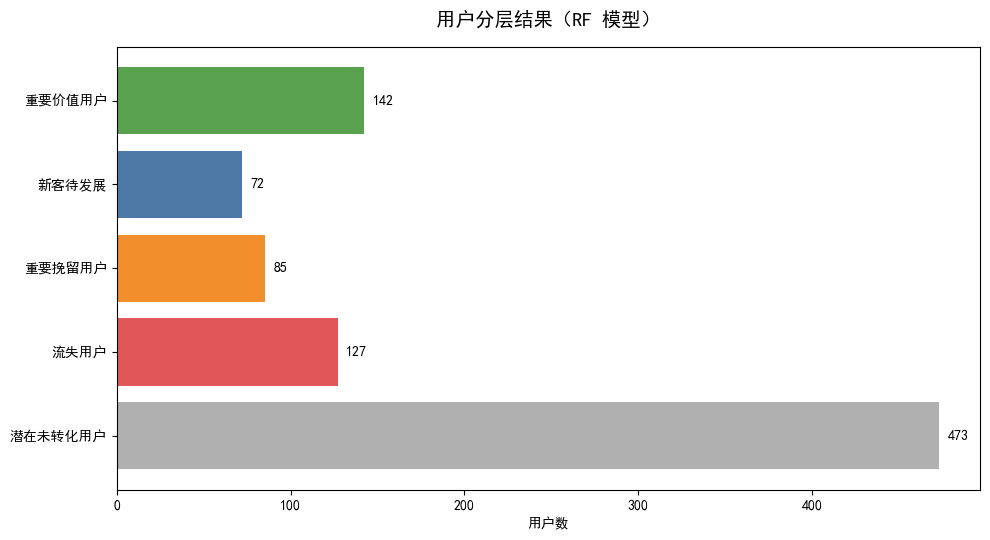

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ['#59a14f', '#4e79a7', '#f28e2b', '#e15759', '#b0b0b0']
bars = ax.barh(seg_df['分层'], seg_df['人数'], color=colors)
ax.invert_yaxis()
ax.set_title('用户分层结果（RF 模型）', fontsize=14, pad=15)
ax.set_xlabel('用户数')
for b, v in zip(bars, seg_df['人数']):
    ax.text(v + 5, b.get_y() + b.get_height()/2, str(v), va='center')
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/rf_segment.png', dpi=150, bbox_inches='tight')
plt.show()

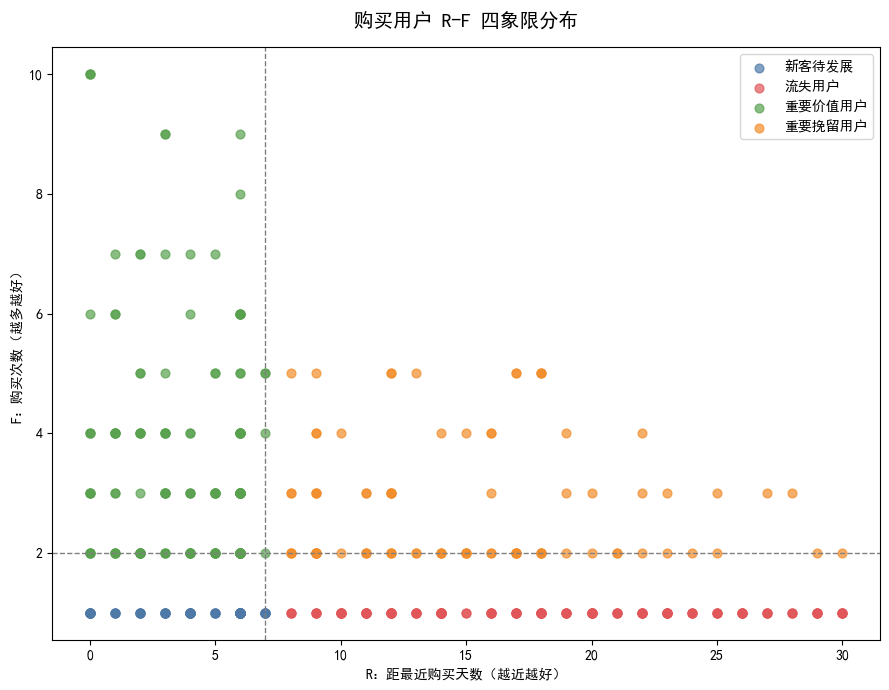

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
seg_colors = {'重要价值用户': '#59a14f', '新客待发展': '#4e79a7',
              '重要挽留用户': '#f28e2b', '流失用户': '#e15759'}
for name, g in buy_df.groupby('segment'):
    ax.scatter(g['R'], g['F'], s=40, alpha=0.7, label=name, color=seg_colors[name])
ax.axvline(r_med, color='gray', ls='--', lw=1)
ax.axhline(f_med, color='gray', ls='--', lw=1)
ax.set_xlabel('R：距最近购买天数（越近越好）')
ax.set_ylabel('F：购买次数（越多越好）')
ax.set_title('购买用户 R-F 四象限分布', fontsize=14, pad=15)
ax.legend()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/rf_quadrant.png', dpi=150, bbox_inches='tight')
plt.show()

**结论：**
- **重要价值用户 142 人**：近期活跃且复购频次高，是核心营收人群，应重点维护。
- **新客待发展 72 人**：近期首次购买、仅买一次，需通过复购激励引导二次购买。
- **重要挽留用户 85 人**：历史复购不错但近期沉寂，适合召回推送。
- **流失用户 127 人**：很久未回购且仅买过一次，召回优先级较低。
- **潜在未转化用户 473 人**：有浏览等行为但未成交，是转化提升的主要池子。

## 四、商品类目效率分析

按类目统计浏览用户数与购买用户数，计算购买转化率。为避免小样本（个位数浏览）造成转化率失真，仅统计浏览用户 ≥ 50 的类目。

```sql
SELECT item_category,
       COUNT(DISTINCT CASE WHEN behavior_type=1 THEN user_id END) AS pv_users,
       COUNT(DISTINCT CASE WHEN behavior_type=4 THEN user_id END) AS buy_users
FROM user_behavior_new
GROUP BY item_category;
```

In [9]:
sql = """
SELECT item_category,
       COUNT(DISTINCT CASE WHEN behavior_type=1 THEN user_id END) AS pv_users,
       COUNT(DISTINCT CASE WHEN behavior_type=4 THEN user_id END) AS buy_users
FROM user_behavior_new GROUP BY item_category
"""
df_cat = query(sql)
df_cat['conv'] = np.where(df_cat['pv_users'] > 0, df_cat['buy_users'] / df_cat['pv_users'], 0)

big = df_cat[df_cat['pv_users'] >= 50].copy()
high = big.sort_values('conv', ascending=False).head(8)
low = big[big['buy_users'] == 0].sort_values('pv_users', ascending=False).head(8)

print(f"类目总数：{len(df_cat)} | 有购买类目：{(df_cat['buy_users']>0).sum()} | 零购买：{(df_cat['buy_users']==0).sum()}")
high[['item_category', 'pv_users', 'buy_users', 'conv']].round(3)

C:\Users\pzk\AppData\Local\Temp\ipykernel_31240\1607654754.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


类目总数：3811 | 有购买类目：514 | 零购买：3297


,item_category,pv_users,buy_users,conv
363,1421,56,6,0.107
879,3424,123,13,0.106
2122,7957,68,7,0.103
778,3064,110,11,0.100
2546,9516,121,11,0.091
2477,9261,62,5,0.081
468,1838,139,11,0.079
2071,7767,68,5,0.074


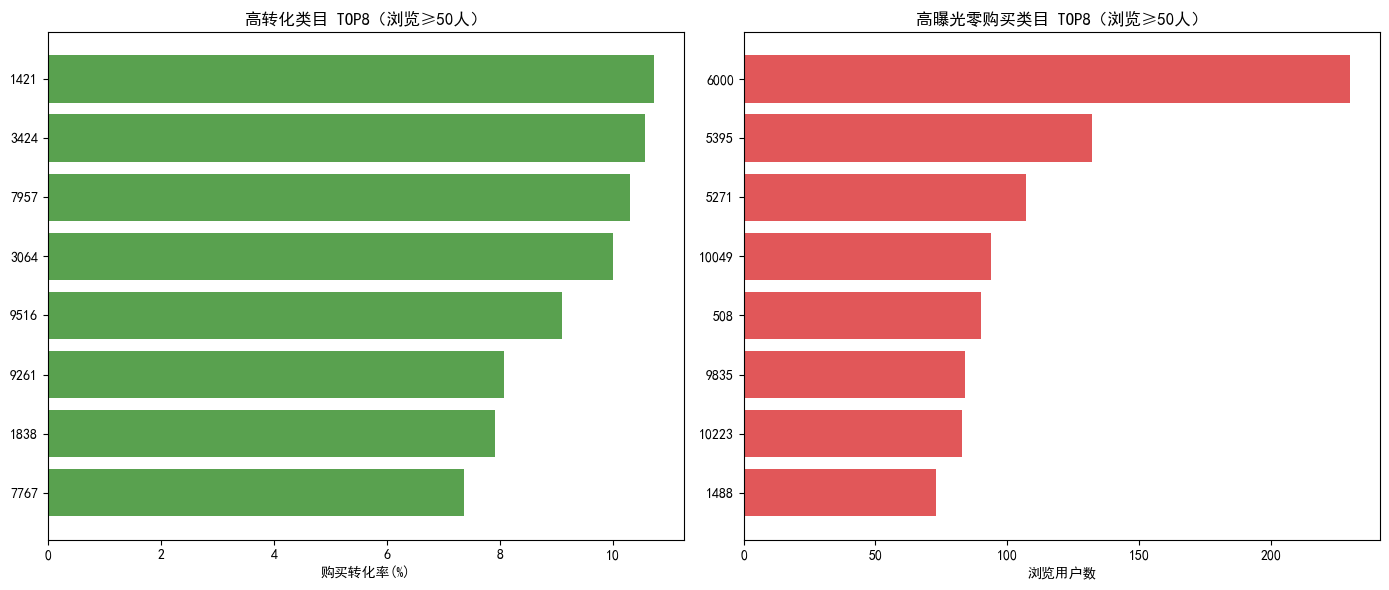

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(high['item_category'].astype(str), high['conv']*100, color='#59a14f')
axes[0].set_title('高转化类目 TOP8（浏览≥50人）', fontsize=12)
axes[0].set_xlabel('购买转化率(%)')
axes[0].invert_yaxis()

axes[1].barh(low['item_category'].astype(str), low['pv_users'], color='#e15759')
axes[1].set_title('高曝光零购买类目 TOP8（浏览≥50人）', fontsize=12)
axes[1].set_xlabel('浏览用户数')
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig(f'{IMG_DIR}/category_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

**结论：**
- 共 3811 个类目，仅 514 个产生购买，长尾类目零成交占比高。
- 部分类目浏览人数多但零购买（高曝光零转化），需排查商品价格、详情页或库存问题。
- 高转化类目（如 1421、3424、7957 等，转化率约 10%）可加大流量倾斜。

## 五、总结与业务建议

### 核心发现
1. 转化链路最大流失在浏览→加购（36%），中后段转化相对健康。
2. 购买用户中重要价值与重要挽留合计约 227 人，是可精细化运营的存量人群；近半数用户尚未转化。
3. 类目效率分化明显，存在一批高曝光零成交类目和一批高转化潜力类目。

### 运营建议
- **前端**：优化详情页与推荐，提升浏览到加购的转化。
- **用户运营**：对重要价值用户做会员维护，对挽留/流失用户分层召回，对新客做复购引导。
- **商品运营**：复盘高曝光零购买类目的转化障碍，给高转化类目倾斜流量。

### 数据局限
- 本分析基于抽样 10 万条样本，结论反映样本结构，不等同于全量大盘。
- 缺少消费金额字段，未做 RFM 中的 M（金额）维度。
- 时间字段精确到小时，R 按天粒度计算。